# Módulo 1 — Exploración del corpus de noticias

**Proyecto:** Market Intelligence Copilot — Pipeline NLP de Volatilidad

Sanity checks sobre `data/processed/news_corpus.parquet` (GDELT + EIA Weekly + **EODHD**),
antes de pasar a FinBERT (Módulo 2). Objetivo: entender **densidad diaria por activo**,
**huecos**, **distribución de fuentes** (y el sesgo a PR), y confirmar que hay **texto**
(cuerpo) para el modelo.

> El corpus ya pasó los tests Point-in-Time. Acá es inspección visual, para saber sobre
> qué datos vamos a construir el diferencial (FinBERT).

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

%matplotlib inline

_root = Path.cwd()
while not (_root / "src").exists() and _root != _root.parent:
    _root = _root.parent
sys.path.insert(0, str(_root))
from src import config

plt.rcParams.update({
    "figure.figsize": (11, 4),
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 11,
})
ASSETS = ["WTI", "BRENT", "HENRY_HUB"]
COLORS = {"WTI": "#1f77b4", "BRENT": "#d62728", "HENRY_HUB": "#2ca02c"}

news = pd.read_parquet(config.NEWS_CORPUS_PARQUET)
prices = pd.read_parquet(config.PRICES_DAILY_PARQUET)
print("Corpus:", news.shape, "| Precios:", prices.shape)

Corpus: (84692, 10) | Precios: (9633, 5)


## 1. Panorama general

In [2]:
print("Columnas:", list(news.columns))
print("\nPor ORIGEN:")
print(news.groupby("origin", observed=True).size().to_string())
print("\nPor ACTIVO:")
print(news.groupby("asset", observed=True).size().to_string())
print("\nPor CALIDAD DE FUENTE:")
print(news.groupby("source_quality", observed=True).size().to_string())
print("\nRango temporal:", news["published_at"].min(), "->", news["published_at"].max())
news.head(3)

Columnas: ['published_at', 'trading_day', 'title', 'body', 'source', 'source_quality', 'url', 'asset', 'origin', 'matched_keywords']

Por ORIGEN:
origin
EIA_WEEKLY     1014
EODHD         83678

Por ACTIVO:
asset
WTI          38858
BRENT        38858
HENRY_HUB     6976

Por CALIDAD DE FUENTE:
source_quality
trusted     1667
other      83025

Rango temporal: 2020-01-01 15:30:00+00:00 -> 2026-06-22 19:56:27+00:00


,published_at,trading_day,title,body,source,source_quality,url,asset,origin,matched_keywords
0,2020-01-01 15:30:00+00:00,2020-01-02 00:00:00+00:00,EIA Weekly Petroleum Status Report: U.S. crude...,,eia.gov,trusted,https://www.eia.gov/petroleum/weekly/#2019-12-27,WTI,EIA_WEEKLY,"[oil, crude]"
1,2020-01-08 15:30:00+00:00,2020-01-08 00:00:00+00:00,EIA Weekly Petroleum Status Report: U.S. crude...,,eia.gov,trusted,https://www.eia.gov/petroleum/weekly/#2020-01-03,WTI,EIA_WEEKLY,"[oil, crude]"
2,2020-01-15 15:30:00+00:00,2020-01-15 00:00:00+00:00,EIA Weekly Petroleum Status Report: U.S. crude...,,eia.gov,trusted,https://www.eia.gov/petroleum/weekly/#2020-01-10,WTI,EIA_WEEKLY,"[oil, crude]"


## 2. Densidad de noticias por mes y por activo

WTI y BRENT comparten las mismas noticias (grupo "oil"), así que muestro **oil (WTI)** y
**gas (Henry Hub)** por separado. Se ve cómo crece el volumen desde 2022 (EODHD amplió
proveedores) y los picos en eventos de mercado.

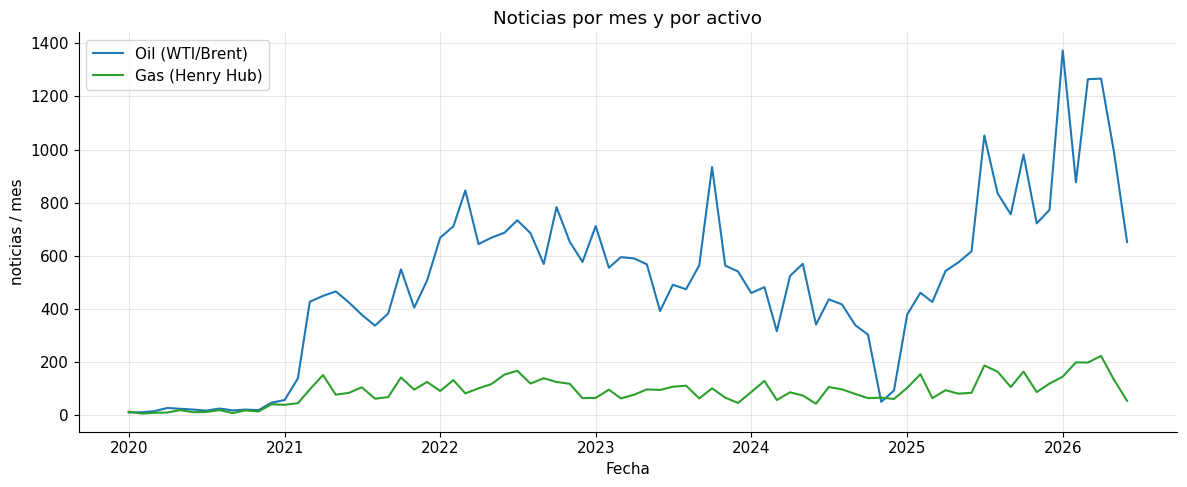

Promedio noticias/mes -> oil: 498 | gas: 89


In [3]:
daily = (news.groupby(["trading_day", "asset"], observed=True).size()
             .unstack("asset", fill_value=0))
daily.index = pd.to_datetime(daily.index)
monthly = daily.resample("MS").sum()

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(monthly.index, monthly["WTI"], color=COLORS["WTI"], label="Oil (WTI/Brent)")
ax.plot(monthly.index, monthly["HENRY_HUB"], color=COLORS["HENRY_HUB"], label="Gas (Henry Hub)")
ax.set_title("Noticias por mes y por activo")
ax.set_ylabel("noticias / mes")
ax.set_xlabel("Fecha")
ax.legend()
fig.tight_layout()
plt.show()

print("Promedio noticias/mes -> oil:", int(monthly["WTI"].mean()), "| gas:", int(monthly["HENRY_HUB"].mean()))

## 3. Cobertura y huecos

Para cada activo: qué porcentaje de los **días de trading** (calendario de precios, 2020+)
tiene al menos una noticia, y cuántos días quedan sin cobertura. Clave para decidir cómo
agregar el sentimiento diario en el Módulo 2.

In [4]:
corpus_start = news["trading_day"].min()
rows = []
for a in ASSETS:
    cal_days = set(prices.loc[(prices["asset"] == a) & (prices["close"].notna()) &
                              (prices["date"] >= corpus_start), "date"])
    news_days = set(news.loc[news["asset"] == a, "trading_day"])
    covered = cal_days & news_days
    gaps = len(cal_days) - len(covered)
    rows.append({
        "asset": a,
        "dias_trading": len(cal_days),
        "dias_con_noticias": len(covered),
        "cobertura_%": round(100 * len(covered) / max(len(cal_days), 1), 1),
        "huecos (dias sin noticias)": gaps,
    })
cobertura = pd.DataFrame(rows).set_index("asset")
cobertura

,dias_trading,dias_con_noticias,cobertura_%,huecos (dias sin noticias)
asset,,,,
WTI,1614,1507,93.4,107
BRENT,1632,1518,93.0,114
HENRY_HUB,1615,1430,88.5,185


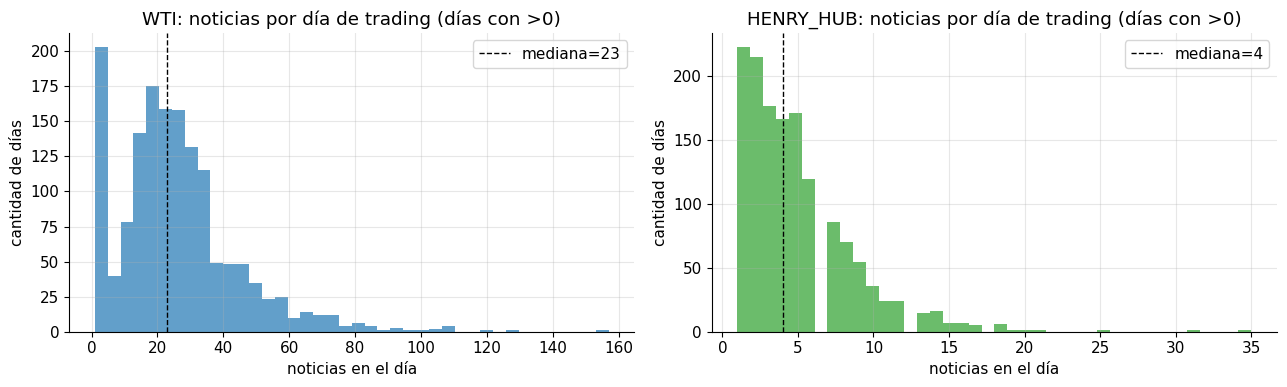

In [5]:
# Distribución de noticias por día de trading (¿días densos vs flacos?)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, a in zip(axes, ["WTI", "HENRY_HUB"]):
    s = daily[a][daily[a] > 0]
    ax.hist(s, bins=40, color=COLORS[a], alpha=0.7)
    ax.set_title(f"{a}: noticias por día de trading (días con >0)")
    ax.set_xlabel("noticias en el día")
    ax.set_ylabel("cantidad de días")
    ax.axvline(s.median(), color="black", ls="--", lw=1, label=f"mediana={int(s.median())}")
    ax.legend()
fig.tight_layout()
plt.show()

## 4. Fuentes y sesgo a PR

EODHD indexa noticias por ticker, así que aparecen muchos **comunicados de prensa**
(globenewswire, etc.) y agregadores. Esto es sentimiento de **sector**, no puro
precio-commodity. El flag `source_quality` permite filtrar a `trusted` si hace falta.

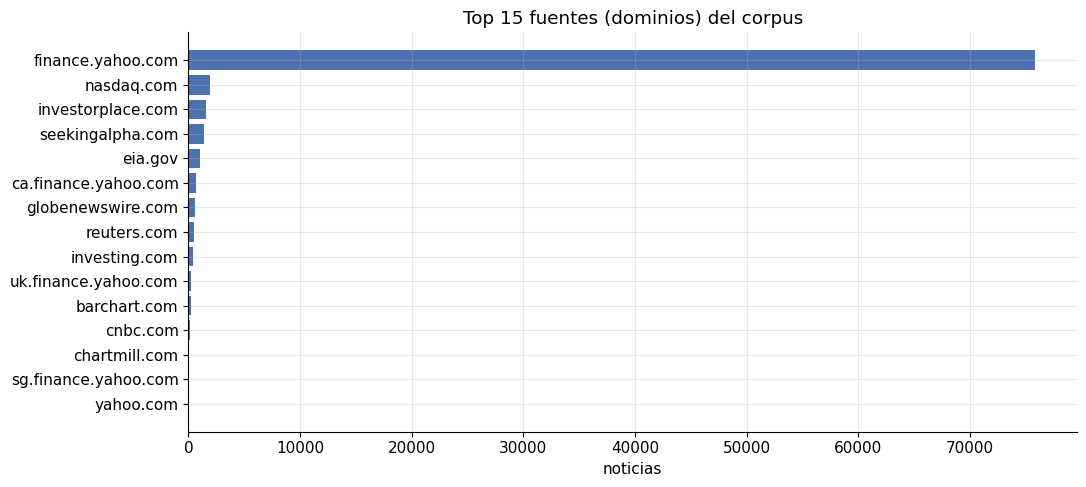

Calidad de fuente:
source_quality
trusted     1667
other      83025

% trusted: 2.0%  (whitelist: reuters/bloomberg/oilprice/eia.gov/...)
Dominios distintos: 20


In [6]:
top = news["source"].value_counts().head(15)
fig, ax = plt.subplots(figsize=(11, 5))
ax.barh(top.index[::-1], top.values[::-1], color="#4c72b0")
ax.set_title("Top 15 fuentes (dominios) del corpus")
ax.set_xlabel("noticias")
fig.tight_layout()
plt.show()

q = news.groupby("source_quality", observed=True).size()
print("Calidad de fuente:")
print(q.to_string())
print(f"\n% trusted: {100 * q.get('trusted', 0) / len(news):.1f}%  (whitelist: reuters/bloomberg/oilprice/eia.gov/...)")
print(f"Dominios distintos: {news['source'].nunique()}")

## 5. Longitud del cuerpo (texto para FinBERT)

EODHD trae **cuerpo completo** (a diferencia de GDELT, que daba solo titular; y EIA, que
son documentos sintéticos con body vacío). Esto es lo que FinBERT va a leer.

Filas con cuerpo (body > 0): 83677 / 84692 (98.8%)
Largo de cuerpo -> mediana: 3601 chars | media: 4534 | max: 104246


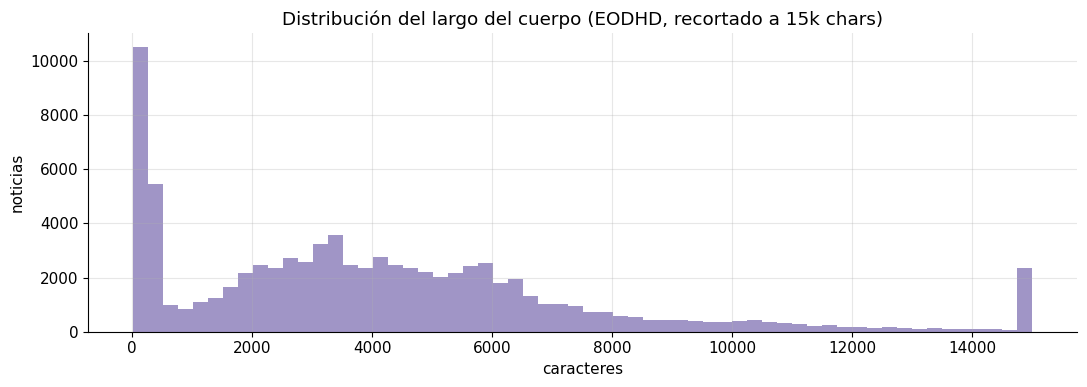

In [7]:
news["body_len"] = news["body"].fillna("").str.len()
con_cuerpo = news[news["body_len"] > 0]
print(f"Filas con cuerpo (body > 0): {len(con_cuerpo)} / {len(news)} ({100*len(con_cuerpo)/len(news):.1f}%)")
print(f"Largo de cuerpo -> mediana: {int(con_cuerpo['body_len'].median())} chars | "
      f"media: {int(con_cuerpo['body_len'].mean())} | max: {int(con_cuerpo['body_len'].max())}")

fig, ax = plt.subplots(figsize=(11, 4))
ax.hist(con_cuerpo["body_len"].clip(upper=15000), bins=60, color="#8172b3", alpha=0.75)
ax.set_title("Distribución del largo del cuerpo (EODHD, recortado a 15k chars)")
ax.set_xlabel("caracteres")
ax.set_ylabel("noticias")
fig.tight_layout()
plt.show()

## Conclusiones

- **Volumen sobrado**: decenas de miles de noticias por activo (oil >> gas), con **cuerpo
  completo** para FinBERT.
- **Cobertura diaria** alta en oil; **Henry Hub más flaco** (menos empresas de gas) — a
  tener en cuenta al agregar sentimiento de gas.
- **Sesgo a PR / sector**: mayoría de fuentes son comunicados/agregadores (`other`); el
  sentimiento es de **sector energético**, no puro precio-commodity. Refinable con
  `source_quality=trusted` o keywords si el Módulo 2 lo pide.
- **Crecimiento 2022+**: más volumen desde que EODHD amplió proveedores.

→ Corpus **sólido y conocido**. Listo para construir el diferencial (FinBERT) sabiendo
sobre qué datos estamos parados.